# MoleculeAI — BACE Bioactivity Prediction

This notebook builds and evaluates a baseline molecular bioactivity classifier using the BACE dataset.

**Important:** This is a computational research exercise. Predictions are not evidence that a compound is a safe or effective medicine.

## Workflow
1. Install and verify dependencies
2. Download/load BACE data
3. Validate SMILES and labels
4. Generate molecular descriptors and Morgan fingerprints
5. Split by molecular scaffold
6. Train a Random Forest model
7. Evaluate and save artifacts
8. Predict on a new SMILES string


In [1]:
%pip install -q rdkit pandas numpy scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

SEED = 42
ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "raw"
MODEL_DIR = ROOT / "models"
DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "bace.csv"
MODEL_PATH = MODEL_DIR / "moleculeai_bace.joblib"
METRICS_PATH = MODEL_DIR / "evaluation_metrics.json"

print("Project directory:", ROOT)
print("RDKit and ML libraries imported successfully.")

Project directory: c:\Users\CT_USER\MoleculeAI\notebooks
RDKit and ML libraries imported successfully.


## 1. Download and load the BACE dataset

The notebook downloads the public BACE benchmark CSV if it is not already present in `data/raw/`. The dataset contains experimental activity labels for compounds associated with the BACE-1 target.

In [3]:
DATA_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv"

if not DATA_PATH.exists():
    print("Downloading BACE dataset...")
    df = pd.read_csv(DATA_URL)
    df.to_csv(DATA_PATH, index=False)
else:
    print("Using existing dataset:", DATA_PATH)
    df = pd.read_csv(DATA_PATH)

print("Raw shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Raw shape: (1513, 595)
Columns: ['mol', 'CID', 'Class', 'Model', 'pIC50', 'MW', 'AlogP', 'HBA', 'HBD', 'RB', 'HeavyAtomCount', 'ChiralCenterCount', 'ChiralCenterCountAllPossible', 'RingCount', 'PSA', 'Estate', 'MR', 'Polar', 'sLi_Key', 'ssBe_Key', 'ssssBem_Key', 'sBH2_Key', 'ssBH_Key', 'sssB_Key', 'ssssBm_Key', 'sCH3_Key', 'dCH2_Key', 'ssCH2_Key', 'tCH_Key', 'dsCH_Key', 'aaCH_Key', 'sssCH_Key', 'ddC_Key', 'tsC_Key', 'dssC_Key', 'aasC_Key', 'aaaC_Key', 'ssssC_Key', 'sNH3_Key', 'sNH2_Key', 'ssNH2_Key', 'dNH_Key', 'ssNH_Key', 'aaNH_Key', 'tN_Key', 'sssNH_Key', 'dsN_Key', 'aaN_Key', 'sssN_Key', 'ddsN_Key', 'aasN_Key', 'ssssN_Key', 'daaN_Key', 'sOH_Key', 'dO_Key', 'ssO_Key', 'aaO_Key', 'aOm_Key', 'sOm_Key', 'sF_Key', 'sSiH3_Key', 'ssSiH2_Key', 'sssSiH_Key', 'ssssSi_Key', 'sPH2_Key', 'ssPH_Key', 'sssP_Key', 'dsssP_Key', 'ddsP_Key', 'sssssP_Key', 'sSH_Key', 'dS_Key', 'ssS_Key', 'aaS_Key', 'dssS_Key', 'ddssS_Key', 'ssssssS_Key', 'Sm_Key', 'sCl_Key', 'sGeH3_Key', 'ssGeH2_Key', 'sssGeH_Key', 'ss

,mol,CID,Class,Model,pIC50,MW,AlogP,HBA,HBD,RB,...,PEOE6 (PEOE6),PEOE7 (PEOE7),PEOE8 (PEOE8),PEOE9 (PEOE9),PEOE10 (PEOE10),PEOE11 (PEOE11),PEOE12 (PEOE12),PEOE13 (PEOE13),PEOE14 (PEOE14),canvasUID
0,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,BACE_1,1,Train,9.154901,431.56979,4.4014,3,2,5,...,53.205711,78.640335,226.85541,107.43491,37.133846,0.000000,7.980170,0.0,0.000000,1
1,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,BACE_2,1,Train,8.853872,657.81073,2.6412,5,4,16,...,73.817162,47.171600,365.67694,174.07675,34.923889,7.980170,24.148668,0.0,24.663788,2
2,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,BACE_3,1,Train,8.698970,591.74091,2.5499,4,3,11,...,70.365707,47.941147,192.40652,255.75255,23.654478,0.230159,15.879790,0.0,24.663788,3
3,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,BACE_4,1,Train,8.698970,591.67828,3.1680,4,3,12,...,56.657166,37.954151,194.35304,202.76335,36.498634,0.980913,8.188327,0.0,26.385181,4
4,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,BACE_5,1,Train,8.698970,629.71283,3.5086,3,3,11,...,78.945702,39.361153,179.71288,220.46130,23.654478,0.230159,15.879790,0.0,26.100143,5


In [4]:
required_columns = {"mol", "Class"}
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"Dataset is missing required columns: {missing}")

df = df[["mol", "Class"]].copy()
df["mol"] = df["mol"].astype(str)
df["Class"] = pd.to_numeric(df["Class"], errors="coerce")
df = df.dropna(subset=["mol", "Class"])
df["Class"] = df["Class"].astype(int)
df = df[df["Class"].isin([0, 1])].drop_duplicates(subset=["mol"]).reset_index(drop=True)

# Keep only valid molecular structures.
valid_mask = df["mol"].map(lambda s: Chem.MolFromSmiles(s) is not None)
invalid_count = int((~valid_mask).sum())
df = df.loc[valid_mask].reset_index(drop=True)

print(f"Usable molecules: {len(df)}")
print(f"Invalid SMILES removed: {invalid_count}")
display(df["Class"].value_counts().rename("count").to_frame())

Usable molecules: 1513
Invalid SMILES removed: 0


,count
Class,
0,822
1,691


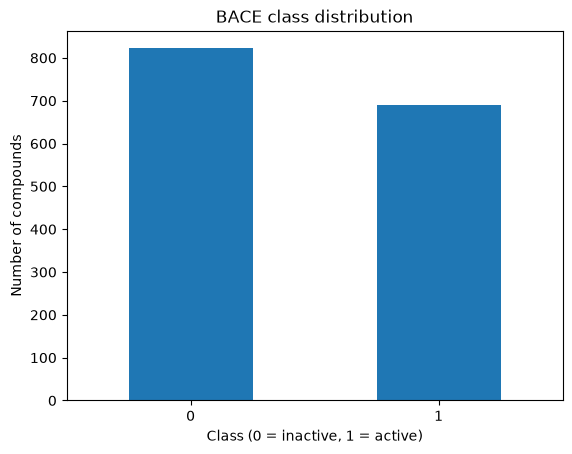

In [5]:
ax = df["Class"].value_counts().sort_index().plot(kind="bar", rot=0)
ax.set_xlabel("Class (0 = inactive, 1 = active)")
ax.set_ylabel("Number of compounds")
ax.set_title("BACE class distribution")
plt.show()

## 2. Convert molecules into numerical features

We combine:
- 2,048-bit Morgan fingerprints (radius 2)
- A small set of interpretable physicochemical descriptors

These features are representations for a machine-learning benchmark, not a complete description of molecular behavior.

In [6]:
FP_SIZE = 2048
fp_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=FP_SIZE)

DESCRIPTOR_NAMES = [
    "MolWt", "MolLogP", "NumHDonors", "NumHAcceptors",
    "NumRotatableBonds", "TPSA", "HeavyAtomCount"
]

def molecule_to_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    descriptors = [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.NumHDonors(mol),
        Descriptors.NumHAcceptors(mol),
        Descriptors.NumRotatableBonds(mol),
        Descriptors.TPSA(mol),
        Descriptors.HeavyAtomCount(mol),
    ]

    fp = fp_generator.GetFingerprint(mol)
    fp_array = np.zeros((FP_SIZE,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, fp_array)

    return np.concatenate([np.asarray(descriptors, dtype=np.float32), fp_array.astype(np.float32)])

X = np.vstack([molecule_to_features(s) for s in df["mol"]])
y = df["Class"].to_numpy(dtype=int)

print("Feature matrix:", X.shape)
print("Labels:", y.shape)

Feature matrix: (1513, 2055)
Labels: (1513,)


## 3. Scaffold-based train/validation/test split

A scaffold split groups compounds by their Bemis–Murcko molecular scaffold, reducing the risk that close structural analogues appear in both training and test sets.

The split below is deterministic. We also inspect class counts because a small scaffold partition can occasionally contain only one class, in which case ROC-AUC is undefined.

In [7]:
def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=True)
    # Group acyclic molecules individually to avoid one giant empty-scaffold group.
    return scaffold if scaffold else f"ACYCLIC::{smiles}"

def scaffold_split(frame, seed=SEED, train_fraction=0.8, valid_fraction=0.1):
    groups = {}
    for idx, smiles in enumerate(frame["mol"]):
        groups.setdefault(get_scaffold(smiles), []).append(idx)

    scaffold_groups = list(groups.values())
    random.Random(seed).shuffle(scaffold_groups)

    n = len(frame)
    train_target = int(n * train_fraction)
    valid_target = int(n * valid_fraction)

    train_idx, valid_idx, test_idx = [], [], []
    for group in scaffold_groups:
        if len(train_idx) < train_target:
            train_idx.extend(group)
        elif len(valid_idx) < valid_target:
            valid_idx.extend(group)
        else:
            test_idx.extend(group)

    return np.array(train_idx), np.array(valid_idx), np.array(test_idx)

train_idx, valid_idx, test_idx = scaffold_split(df)

for name, idx in [("train", train_idx), ("validation", valid_idx), ("test", test_idx)]:
    print(name, "n =", len(idx), "class counts =", np.bincount(y[idx], minlength=2))

if min(len(train_idx), len(valid_idx), len(test_idx)) == 0:
    raise ValueError("A split is empty. Inspect scaffold grouping and dataset.")


train n = 1210 class counts = [644 566]
validation n = 154 class counts = [90 64]
test n = 149 class counts = [88 61]


## 4. Train a Random Forest baseline

The validation partition is used for a preliminary check. The test partition is held out for final evaluation. Do not repeatedly tune model choices against the test results.

In [8]:
X_train, y_train = X[train_idx], y[train_idx]
X_valid, y_valid = X[valid_idx], y[valid_idx]
X_test, y_test = X[test_idx], y[test_idx]

model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Training complete.")

Training complete.


In [9]:
def calculate_metrics(estimator, X_part, y_part):
    pred = estimator.predict(X_part)
    prob = estimator.predict_proba(X_part)[:, list(estimator.classes_).index(1)]

    metrics = {
        "n_samples": int(len(y_part)),
        "accuracy": float(accuracy_score(y_part, pred)),
        "precision": float(precision_score(y_part, pred, zero_division=0)),
        "recall": float(recall_score(y_part, pred, zero_division=0)),
        "f1": float(f1_score(y_part, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_part, prob)) if len(np.unique(y_part)) == 2 else None,
        "pr_auc": float(average_precision_score(y_part, prob)) if len(np.unique(y_part)) == 2 else None,
        "class_counts": {
            str(k): int(v) for k, v in zip(*np.unique(y_part, return_counts=True))
        }
    }
    return metrics, pred, prob

valid_metrics, valid_pred, valid_prob = calculate_metrics(model, X_valid, y_valid)
print("Validation metrics")
print(json.dumps(valid_metrics, indent=2))

Validation metrics
{
  "n_samples": 154,
  "accuracy": 0.8636363636363636,
  "precision": 0.7945205479452054,
  "recall": 0.90625,
  "f1": 0.8467153284671532,
  "roc_auc": 0.9274305555555555,
  "pr_auc": 0.8540251838053523,
  "class_counts": {
    "0": 90,
    "1": 64
  }
}


## 5. Final held-out test evaluation

Interpret metrics alongside test-set size and class balance. A single benchmark score is not proof of prospective drug-discovery performance.

Test metrics
{
  "n_samples": 149,
  "accuracy": 0.8120805369127517,
  "precision": 0.746268656716418,
  "recall": 0.819672131147541,
  "f1": 0.78125,
  "roc_auc": 0.9012667660208644,
  "pr_auc": 0.8470043818236355,
  "class_counts": {
    "0": 88,
    "1": 61
  }
}

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.81      0.84        88
           1       0.75      0.82      0.78        61

    accuracy                           0.81       149
   macro avg       0.81      0.81      0.81       149
weighted avg       0.82      0.81      0.81       149



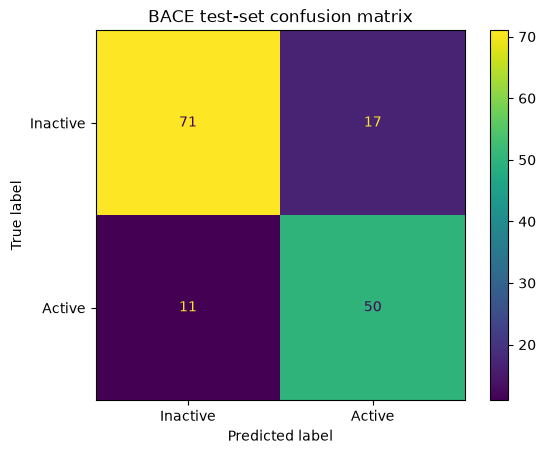

In [10]:
test_metrics, test_pred, test_prob = calculate_metrics(model, X_test, y_test)
print("Test metrics")
print(json.dumps(test_metrics, indent=2))
print("\nClassification report:")
print(classification_report(y_test, test_pred, zero_division=0))

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Inactive", "Active"]).plot()
plt.title("BACE test-set confusion matrix")
plt.show()

## 6. Save the model and evaluation results

In [11]:
joblib.dump(model, MODEL_PATH)

artifact = {
    "dataset": "BACE",
    "target": "BACE-1 bioactivity classification",
    "feature_type": "7 descriptors + 2048-bit Morgan fingerprint (radius 2)",
    "split": "Bemis-Murcko scaffold split",
    "seed": SEED,
    "test_metrics": test_metrics
}
with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(artifact, f, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved metrics:", METRICS_PATH)

Saved model: c:\Users\CT_USER\MoleculeAI\notebooks\models\moleculeai_bace.joblib
Saved metrics: c:\Users\CT_USER\MoleculeAI\notebooks\models\evaluation_metrics.json


## 7. Predict a new molecule

Change `new_smiles` to a valid SMILES string. The output is a model classification and model score for the active class. It is **not** a clinical probability, a binding measurement, or a safety assessment.

In [12]:
def predict_smiles(smiles, estimator=model):
    features = molecule_to_features(smiles).reshape(1, -1)
    predicted_class = int(estimator.predict(features)[0])
    active_index = list(estimator.classes_).index(1)
    active_score = float(estimator.predict_proba(features)[0, active_index])

    return {
        "smiles": smiles,
        "predicted_class": predicted_class,
        "active_class_model_score": active_score,
        "interpretation": "Predicted active" if predicted_class == 1 else "Predicted inactive",
        "warning": "Computational benchmark prediction only; requires experimental validation."
    }

new_smiles = "CCO"
prediction = predict_smiles(new_smiles)
print(json.dumps(prediction, indent=2))

{
  "smiles": "CCO",
  "predicted_class": 0,
  "active_class_model_score": 0.33610987845055557,
  "interpretation": "Predicted inactive",
  "warning": "Computational benchmark prediction only; requires experimental validation."
}


## 8. Limitations and next steps

- BACE labels reflect a specific assay context and should not be generalized to other targets.
- Scaffold splitting is more demanding than a random split, but does not replace external prospective validation.
- The Random Forest score may be poorly calibrated; calibration should be assessed on suitable held-out data.
- This model does not predict clinical efficacy, dose, patient response, or overall drug safety.
- Next: compare against a simple baseline, tune using validation data only, test on an external dataset, quantify uncertainty, and document dataset provenance.